# Module F: object identification and counting of simple shapes (project brief 6) + full analysis
Five classes (square, circle, triangle, pentagon, hexagon). Delivers: **dataset folder with a train/test split** (`shapes_dataset_*/`), preprocessing + feature extraction, rule-based and ML classification (KNN / SVM / Random Forest / logistic regression), **accuracy, macro-F1, confusion matrices, TP/FP/FN/TN, ROC / PR**, an **object-counting demo** (predicted vs true count, detection TP/FP/FN), and the extensions (rotated shapes, overlapping shapes, multi-object scenes).

**Nothing repeats:** the dataset folder, feature table, trained models, experiments and counting results are written to disk once and loaded on later runs; everything is also kept in memory. Flags `RETRAIN` and `RECOUNT` force a recompute.

The last section reads the output folder of modules B/C/E (`pipeline_out_*`) for EDA and a classical-CV baseline on the pipeline's own images.

In [1]:
import os, sys, json, time, math, hashlib, subprocess, warnings
import numpy as np
def need(mod, pip=None):
    try: __import__(mod)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip or mod])
for m, p in (("cv2", "opencv-python-headless"), ("sklearn", "scikit-learn"), ("pandas", None), ("scipy", None), ("matplotlib", None), ("PIL", "pillow"), ("joblib", None)): need(m, p)
import cv2, joblib, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.signal import find_peaks
from scipy.optimize import linear_sum_assignment
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score)
warnings.filterwarnings("ignore"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
# ---- keep-in-memory helper: an object is built once per kernel; re-running a cell re-uses it ----
_mem = globals().setdefault("_mem", {})
def once(name, key, build, verbose=True):
    if name in globals() and _mem.get(name) == key:
        if verbose: print(f"[memory] {name}: already loaded, nothing recomputed")
        return globals()[name]
    globals()[name] = build(); _mem[name] = key; return globals()[name]


In [2]:
# ======== settings ========
QUICK   = True                                      # True: small run (minutes). False: full-size dataset
SEED    = 0
SHAPES  = ["square", "circle", "triangle", "pentagon", "hexagon"]     # the five classes of the brief
SIZE    = 256
N_PER   = dict(train=120, test=40) if QUICK else dict(train=600, test=200)   # images per class
N_SCENES = 40 if QUICK else 200                     # multi-object scenes for counting
MIN_AREA = 150                                      # px^2, smaller blobs are treated as noise when counting
BOOT    = 500 if QUICK else 3000                    # bootstrap resamples
TAG     = f"{'quick' if QUICK else 'full'}_s{SEED}"
ROOT    = f"shapes_dataset_{TAG}"                   # dataset folder: train/ test/ scenes/ + csv files
OUT_F   = f"analysis_F_{TAG}"                       # features, models, figures, tables
PIPE_OUT = "pipeline_out_quick_shapes_4c_500e_256"  # optional: output folder of modules B/C/E (used in the last section)
PIPE_CLASSES = ["circle", "square", "triangle", "line"]
NS = len(SHAPES); BGS = ["plain_light", "plain_dark", "gradient", "noisy"]
os.makedirs(OUT_F, exist_ok=True); os.makedirs(ROOT, exist_ok=True); KEY = (QUICK, SEED, tuple(SHAPES), SIZE, tuple(N_PER.items()), N_SCENES)
print("dataset folder:", ROOT, "| analysis outputs:", OUT_F)


dataset folder: shapes_dataset_quick_s0 | analysis outputs: analysis_F_quick_s0


In [3]:
# ---------- generator: shapes on varied backgrounds, plus multi-object scenes ----------
def make_bg(kind, rng):
    if kind == "plain_light": v = int(rng.integers(200, 256)); return np.full((SIZE, SIZE, 3), v, np.uint8), float(v)
    if kind == "plain_dark": v = int(rng.integers(0, 56)); return np.full((SIZE, SIZE, 3), v, np.uint8), float(v)
    if kind == "gradient":
        a, b = rng.integers(150, 256, 2); g = np.linspace(a, b, SIZE)[None, :, None] * np.ones((SIZE, 1, 3)); return g.astype(np.uint8), float((a + b) / 2)
    base = int(rng.integers(190, 256)); img = base + rng.normal(0, rng.uniform(12, 25), (SIZE, SIZE, 3))          # noisy
    return np.clip(img, 0, 255).astype(np.uint8), float(base)

def pick_fg(bg_mean, rng):
    base = rng.integers(0, 80) if bg_mean > 128 else rng.integers(175, 256)
    return tuple(int(v) for v in np.clip(base + rng.integers(-35, 36, 3), 0, 255))

def shape_poly(c, cx, cy, r, rot, squash):
    n = {"square": 4, "triangle": 3, "pentagon": 5, "hexagon": 6}[c]; a = rot + np.arange(n) * 2 * np.pi / n
    return np.c_[cx + r * np.cos(a), cy + r * np.sin(a) * squash]

def draw_shape(img, c, cx, cy, r, rot, squash, color, filled, thick):
    if c == "circle": cv2.ellipse(img, (int(cx), int(cy)), (int(r), max(int(r * squash), 2)), math.degrees(rot), 0, 360, color, -1 if filled else thick, cv2.LINE_AA)
    else:
        pts = shape_poly(c, cx, cy, r, rot, squash).astype(np.int32)
        if filled: cv2.fillPoly(img, [pts], color, cv2.LINE_AA)
        else: cv2.polylines(img, [pts], True, color, thick, cv2.LINE_AA)

def render_single(c, rng):
    bg = BGS[int(rng.integers(len(BGS)))]; img, bg_mean = make_bg(bg, rng); fg = pick_fg(bg_mean, rng)
    r = rng.uniform(22, 100); mg = r * 1.05; cx, cy = rng.uniform(mg, SIZE - mg, 2); rot = rng.uniform(0, 2 * np.pi); sq = rng.uniform(.85, 1.)
    filled = bool(rng.random() < .6); th = int(rng.integers(3, 8)); draw_shape(img, c, cx, cy, r, rot, sq, fg, filled, th)
    blur, noise = 0, 0.
    if rng.random() < .3: blur = int(rng.choice([3, 5])); img = cv2.GaussianBlur(img, (blur, blur), 0)
    if bg != "noisy" and rng.random() < .3: noise = float(rng.uniform(3, 10)); img = np.clip(img + rng.normal(0, noise, img.shape), 0, 255).astype(np.uint8)
    fgg = float(np.mean(fg))
    return img, dict(bg=bg, filled=filled, rot_deg=float(np.degrees(rot) % 360), radius=float(r), cx=float(cx), cy=float(cy), squash=float(sq), thick=th, blur=blur,
                     noise=noise, bg_mean=bg_mean, fg_gray=fgg, contrast=abs(fgg - bg_mean))

def render_scene(rng):
    bg = str(rng.choice(["plain_light", "gradient", "noisy"])); img, bg_mean = make_bg(bg, rng); fg = pick_fg(bg_mean, rng)
    k = int(rng.integers(1, 7)); want_overlap = bool(rng.random() < .4 and k >= 2); objs = []
    for j in range(k):
        for _ in range(300):
            c = SHAPES[int(rng.integers(NS))]; r = rng.uniform(20, 38)
            if want_overlap and objs and (j == 1 or rng.random() < .5):               # place it partly on top of an existing object
                p = objs[int(rng.integers(len(objs)))]; a = rng.uniform(0, 2 * np.pi); d = (p["r"] + r) * rng.uniform(.55, .8); cx, cy = p["cx"] + d * np.cos(a), p["cy"] + d * np.sin(a)
            else: cx, cy = rng.uniform(r * 1.1, SIZE - r * 1.1, 2)
            if not (r * 1.1 <= cx <= SIZE - r * 1.1 and r * 1.1 <= cy <= SIZE - r * 1.1): continue
            gap = min([np.hypot(cx - o["cx"], cy - o["cy"]) - (r + o["r"]) for o in objs], default=1e9)
            if want_overlap or gap > 12: break
        else: continue
        o = dict(cls=c, cx=float(cx), cy=float(cy), r=float(r), rot=float(rng.uniform(0, 2 * np.pi)), squash=float(rng.uniform(.9, 1.))); objs.append(o)
        draw_shape(img, c, o["cx"], o["cy"], r, o["rot"], o["squash"], fg, True, 3)
    pairs = sum(np.hypot(a["cx"] - b["cx"], a["cy"] - b["cy"]) < .95 * (a["r"] + b["r"]) for i, a in enumerate(objs) for b in objs[i + 1:])
    return img, dict(bg=bg, n_objects=len(objs), overlap_pairs=int(pairs), overlap=bool(pairs > 0)), objs

def build_dataset():
    t0 = time.time(); rows = []
    for split in ("train", "test"):
        for ci, c in enumerate(SHAPES):
            os.makedirs(f"{ROOT}/{split}/{c}", exist_ok=True)
            for i in range(N_PER[split]):
                img, m = render_single(c, np.random.default_rng([SEED, 1 if split == "train" else 2, ci, i])); p = f"{ROOT}/{split}/{c}/{c}_{i:04d}.png"
                cv2.imwrite(p, cv2.cvtColor(img, cv2.COLOR_RGB2BGR)); m.update(split=split, cls=c, path=p); rows.append(m)
    meta = pd.DataFrame(rows); meta.to_csv(f"{ROOT}/metadata.csv", index=False)
    os.makedirs(f"{ROOT}/scenes", exist_ok=True); srows, gt = [], {}
    for i in range(N_SCENES):
        img, m, objs = render_scene(np.random.default_rng([SEED, 99, i])); p = f"{ROOT}/scenes/scene_{i:04d}.png"; cv2.imwrite(p, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
        m.update(scene=i, path=p); srows.append(m); gt[str(i)] = objs
    pd.DataFrame(srows).to_csv(f"{ROOT}/scenes.csv", index=False); json.dump(gt, open(f"{ROOT}/scene_objects.json", "w"))
    print(f"dataset built in {time.time() - t0:.0f}s -> {ROOT}"); return meta

def load_dataset():
    if not os.path.exists(f"{ROOT}/metadata.csv"): build_dataset()
    else: print("dataset folder already exists, not regenerated:", ROOT)
    return pd.read_csv(f"{ROOT}/metadata.csv"), pd.read_csv(f"{ROOT}/scenes.csv"), json.load(open(f"{ROOT}/scene_objects.json"))


In [4]:
# ---------- preprocessing (threshold -> clean -> contours) and shape features ----------
FEATS = ["circularity", "solidity", "extent", "rect_fill", "aspect", "circ_ratio", "ecc", "v2", "v4", "radial_cv", "radial_ratio", "n_peaks"] + [f"hu{i}" for i in range(1, 8)]
FID = hashlib.md5(",".join(FEATS).encode()).hexdigest()[:6]
K3 = np.ones((3, 3), np.uint8)

def read_rgb(p): return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)

def segment(img):
    """RGB or gray image -> binary mask with the objects white, whatever the background (Otsu + border check + morphological clean-up)."""
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim == 3 else img; g = cv2.GaussianBlur(g, (5, 5), 0)
    _, th = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if np.concatenate([th[0], th[-1], th[:, 0], th[:, -1]]).mean() > 127: th = 255 - th          # background must be black
    return cv2.morphologyEx(cv2.morphologyEx(th, cv2.MORPH_OPEN, K3), cv2.MORPH_CLOSE, K3)

def contours_of(th, min_area=0):
    cs, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); return [c for c in cs if cv2.contourArea(c) >= max(min_area, 1)]

def contour_features(c):
    A, P = cv2.contourArea(c), cv2.arcLength(c, True)
    if A < 5 or P < 5 or len(c) < 5: return None
    HA = cv2.contourArea(cv2.convexHull(c)); x, y, w, h = cv2.boundingRect(c); (_, _), (rw, rh), _ = cv2.minAreaRect(c); (_, _), er = cv2.minEnclosingCircle(c)
    (_, _), (MA, ma), _ = cv2.fitEllipse(c); M = cv2.moments(c); cx, cy = M["m10"] / M["m00"], M["m01"] / M["m00"]
    d = np.hypot(c[:, 0, 0] - cx, c[:, 0, 1] - cy); t = np.linspace(0, len(d), 180, endpoint=False); prof = np.interp(t, np.arange(len(d)), d)
    k = 5; sm = np.convolve(np.r_[prof[-k:], prof, prof[:k]], np.ones(2 * k + 1) / (2 * k + 1), "same")[k:-k]
    pk, _ = find_peaks(np.r_[sm, sm], prominence=.03 * sm.mean()); n_peaks = int(((pk >= 90) & (pk < 270)).sum())   # one full period of the doubled profile
    hu = cv2.HuMoments(M).flatten(); hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    f = dict(area=A, perimeter=P, cx=cx, cy=cy, circularity=4 * np.pi * A / P ** 2, solidity=A / max(HA, 1e-6), extent=A / max(w * h, 1), rect_fill=A / max(rw * rh, 1),
             aspect=min(rw, rh) / max(rw, rh, 1e-6), circ_ratio=A / (np.pi * er ** 2 + 1e-6), ecc=math.sqrt(max(0., 1 - (min(MA, ma) / max(MA, ma)) ** 2)),
             v2=len(cv2.approxPolyDP(c, .02 * P, True)), v4=len(cv2.approxPolyDP(c, .04 * P, True)), radial_cv=d.std() / d.mean(), radial_ratio=d.min() / d.max(), n_peaks=n_peaks)
    f.update({f"hu{i + 1}": float(hu[i]) for i in range(7)}); return f

def image_features(img):
    cs = contours_of(segment(img)); fs = [contour_features(c) for c in sorted(cs, key=cv2.contourArea, reverse=True)[:1]]
    return fs[0] if fs and fs[0] else None

def extract_all(meta):
    f = f"{OUT_F}/features.csv"
    if os.path.exists(f): print("features: loaded", f); return pd.read_csv(f)
    t0 = time.time(); rows = []
    for _, r in meta.iterrows():
        ft = image_features(read_rgb(r["path"])); rows.append({**r.to_dict(), **(ft or {k: np.nan for k in FEATS})})
    df = pd.DataFrame(rows); n0 = len(df); df = df.dropna(subset=FEATS).reset_index(drop=True); df.to_csv(f, index=False)
    print(f"features: extracted for {len(df)}/{n0} images in {time.time() - t0:.0f}s -> {f}"); return df

def rule_predict(df):
    """Classical rule-based baseline: circularity + polygon vertex count (no learning)."""
    out = []
    for _, r in df.iterrows():
        v = r["v2"]
        if r["circularity"] > .93 or v >= 8: out.append("circle")
        elif v <= 3: out.append("triangle")
        elif v == 4: out.append("square")
        elif v == 5: out.append("pentagon")
        else: out.append("hexagon")
    return np.array(out)


In [5]:
# ---------- metrics helpers: accuracy, macro-F1, TP/FP/FN/TN per class, confusion matrix, bootstrap CIs ----------
def cm_np(y, p, n=NS): return np.bincount(np.asarray(y) * n + np.asarray(p), minlength=n * n).reshape(n, n)
def macro_f1_cm(cm):
    tp = np.diag(cm); d = 2 * tp + cm.sum(0) - tp + cm.sum(1) - tp; return float(np.mean(np.where(d > 0, 2 * tp / np.maximum(d, 1), 0)))
def boot_ci(y, p, rng, n=BOOT):
    idx = rng.integers(0, len(y), (n, len(y))); acc, f1 = np.empty(n), np.empty(n)
    for i in range(n): c = cm_np(y[idx[i]], p[idx[i]]); acc[i] = np.trace(c) / c.sum(); f1[i] = macro_f1_cm(c)
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])
def tpfp_table(y, p, classes=SHAPES):
    cm = cm_np(y, p, len(classes)); tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
    return pd.DataFrame(dict(support=cm.sum(1), TP=tp, FP=fp, FN=fn, TN=tn, precision=tp / np.maximum(tp + fp, 1), recall_TPR=tp / np.maximum(tp + fn, 1),
                             specificity_TNR=tn / np.maximum(tn + fp, 1), FPR=fp / np.maximum(fp + tn, 1), F1=2 * tp / np.maximum(2 * tp + fp + fn, 1)), index=classes)
def plot_cm(ax, cm, classes, title):
    n = cm / np.maximum(cm.sum(1, keepdims=True), 1); ax.imshow(n, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(classes)):
        for j in range(len(classes)): ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="white" if n[i, j] > .5 else "black")
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=7); ax.set_yticklabels(classes, fontsize=7)
    ax.set_title(title, fontsize=9); ax.set_xlabel("predicted", fontsize=7); ax.set_ylabel("true", fontsize=7)


## 1. Dataset and EDA

dataset built in 10s -> shapes_dataset_quick_s0
train 600 | test 200 | scenes 40 | classes ['square', 'circle', 'triangle', 'pentagon', 'hexagon']


split,test,train
cls,,
square,40,120
circle,40,120
triangle,40,120
pentagon,40,120
hexagon,40,120


image shapes found (sampled 200): {(256, 256, 3)}
exact duplicate files: 0 | identical images in BOTH train and test (leakage): 0

background type x split:


split,test,train
bg,,
gradient,51,157
noisy,52,146
plain_dark,47,151
plain_light,50,146


filled vs outline: {True: 487, False: 313}


,count,mean,std,min,25%,50%,75%,max
radius,800.0,59.58,21.96,22.10,41.92,58.61,78.02,99.77
rot_deg,800.0,182.63,103.16,0.11,97.94,186.81,267.11,359.98
bg_mean,800.0,170.98,84.82,0.00,153.88,209.00,230.12,255.00
fg_gray,800.0,83.80,75.64,0.00,28.92,55.33,100.83,255.00
contrast,800.0,176.72,31.74,74.67,155.33,177.17,198.75,249.33
noise,800.0,1.47,2.86,0.00,0.00,0.00,0.00,10.00
blur,800.0,1.24,1.93,0.00,0.00,0.00,3.00,5.00
thick,800.0,4.98,1.41,3.00,4.00,5.00,6.00,7.00


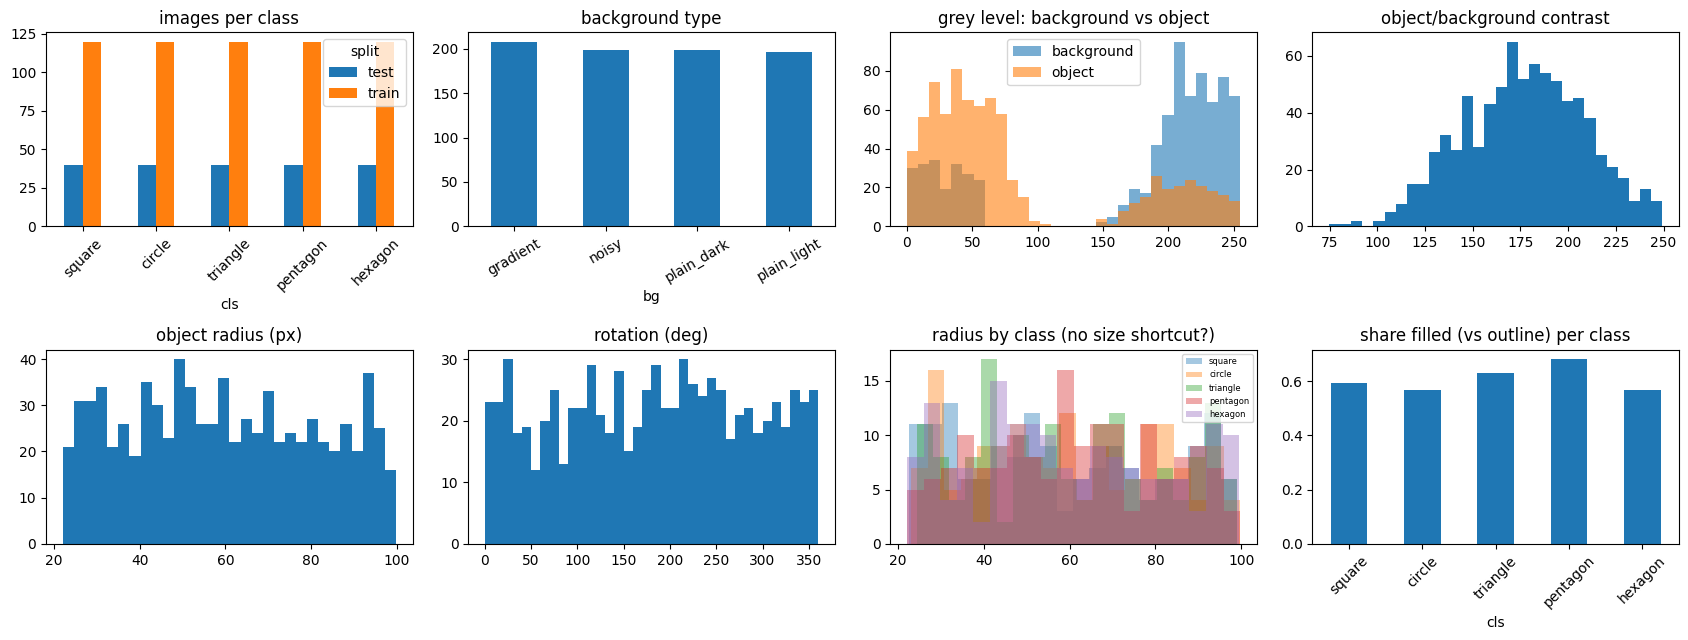

nuisance check, radius differs between classes? Kruskal-Wallis p = 0.810 (large p = no size shortcut)


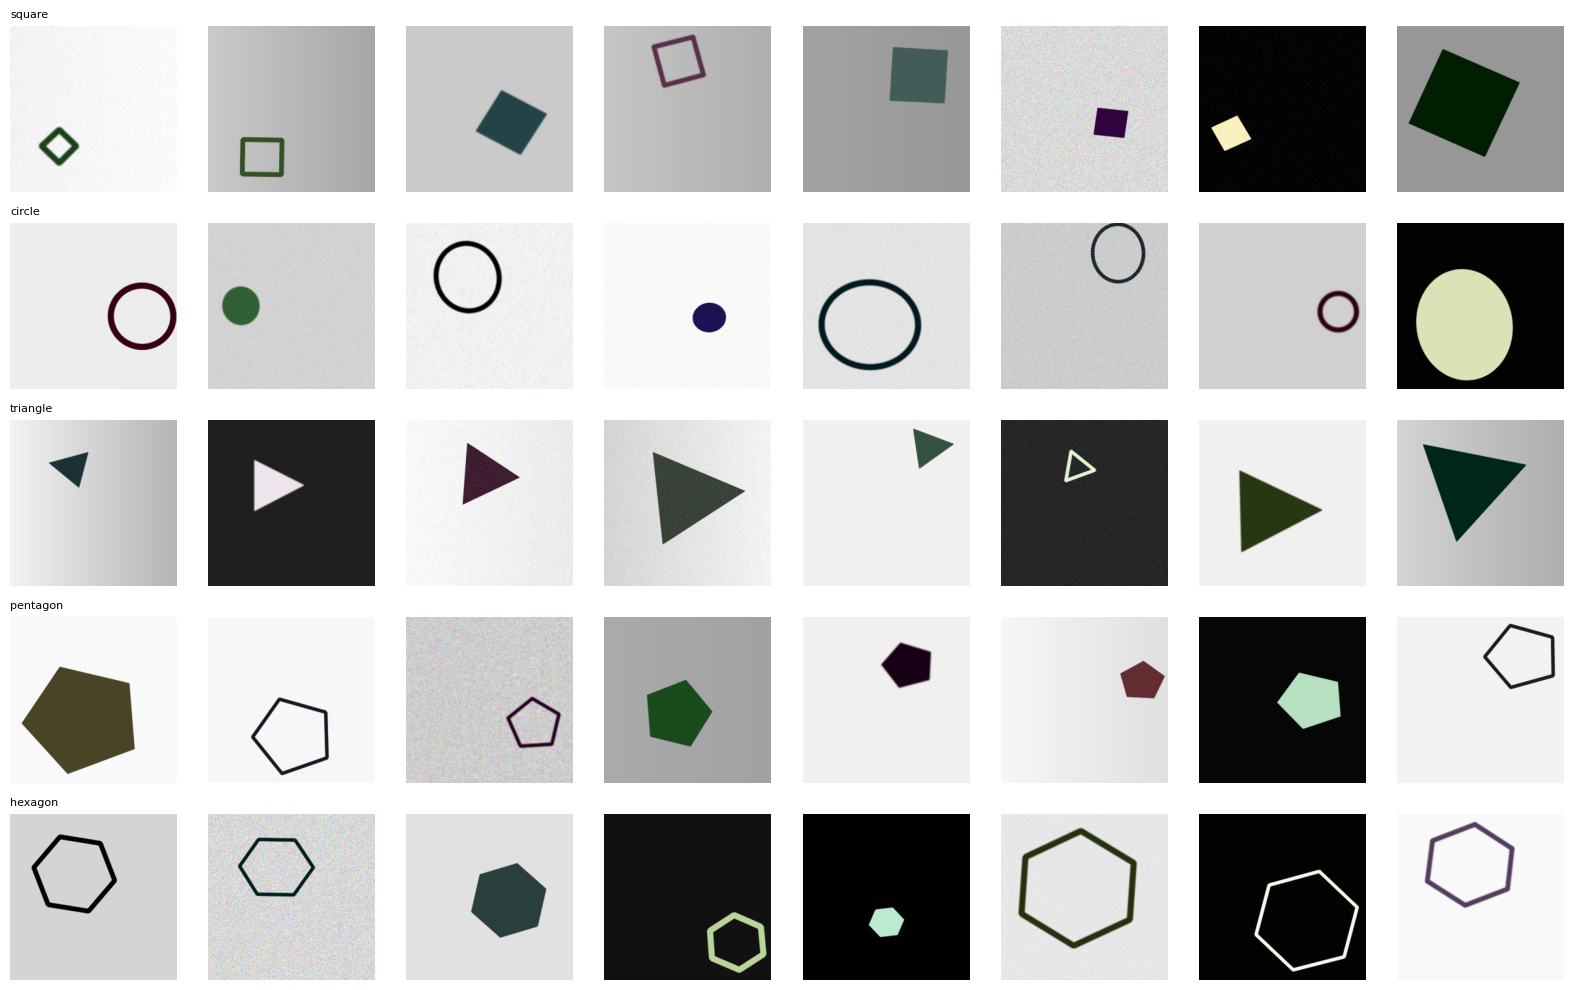

In [6]:
# ---------- EDA 1: the dataset folder (class balance, image size, duplicates / leakage, background and colour variation) ----------
meta, scenes, scene_gt = once("DS", KEY, load_dataset)
tr, te = meta[meta.split == "train"], meta[meta.split == "test"]
print(f"train {len(tr)} | test {len(te)} | scenes {len(scenes)} | classes {SHAPES}")
display(pd.crosstab(meta.cls, meta.split).loc[SHAPES])
shapes_ok = {read_rgb(p).shape for p in meta.path.sample(min(len(meta), 200), random_state=0)}; print("image shapes found (sampled 200):", shapes_ok)
h = meta.path.map(lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()); dup = h[h.duplicated(keep=False)]
leak = set(h[meta.split == "train"]) & set(h[meta.split == "test"]); print(f"exact duplicate files: {len(dup)} | identical images in BOTH train and test (leakage): {len(leak)}")
print("\nbackground type x split:"); display(pd.crosstab(meta.bg, meta.split)); print("filled vs outline:", meta.filled.value_counts().to_dict())
display(meta[["radius", "rot_deg", "bg_mean", "fg_gray", "contrast", "noise", "blur", "thick"]].describe().T.round(2))
fig, ax = plt.subplots(2, 4, figsize=(17, 6.5))
meta.groupby(["split", "cls"]).size().unstack(0).loc[SHAPES].plot.bar(ax=ax[0, 0], title="images per class"); ax[0, 0].tick_params(axis="x", rotation=45)
meta.bg.value_counts().plot.bar(ax=ax[0, 1], title="background type"); ax[0, 1].tick_params(axis="x", rotation=30)
ax[0, 2].hist(meta.bg_mean, 30, alpha=.6, label="background"); ax[0, 2].hist(meta.fg_gray, 30, alpha=.6, label="object"); ax[0, 2].set_title("grey level: background vs object"); ax[0, 2].legend()
ax[0, 3].hist(meta.contrast, 30); ax[0, 3].set_title("object/background contrast")
ax[1, 0].hist(meta.radius, 30); ax[1, 0].set_title("object radius (px)"); ax[1, 1].hist(meta.rot_deg, 36); ax[1, 1].set_title("rotation (deg)")
for c in SHAPES: ax[1, 2].hist(meta[meta.cls == c].radius, 20, alpha=.4, label=c)
ax[1, 2].set_title("radius by class (no size shortcut?)"); ax[1, 2].legend(fontsize=6)
meta.groupby("cls").filled.mean().loc[SHAPES].plot.bar(ax=ax[1, 3], title="share filled (vs outline) per class"); ax[1, 3].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{OUT_F}/eda_dataset.png", dpi=110); plt.show()
ks = stats.kruskal(*[meta[meta.cls == c].radius for c in SHAPES]); print(f"nuisance check, radius differs between classes? Kruskal-Wallis p = {ks.pvalue:.3f} (large p = no size shortcut)")
fig, ax = plt.subplots(NS, 8, figsize=(16, 2 * NS))
for i, c in enumerate(SHAPES):
    for j, p in enumerate(meta[(meta.cls == c) & (meta.split == "train")].path.iloc[:8]): ax[i, j].imshow(read_rgb(p)); ax[i, j].axis("off")
    ax[i, 0].set_title(c, fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_F}/sample_images.png", dpi=100); plt.show()


## 2. Preprocessing, features and feature analysis

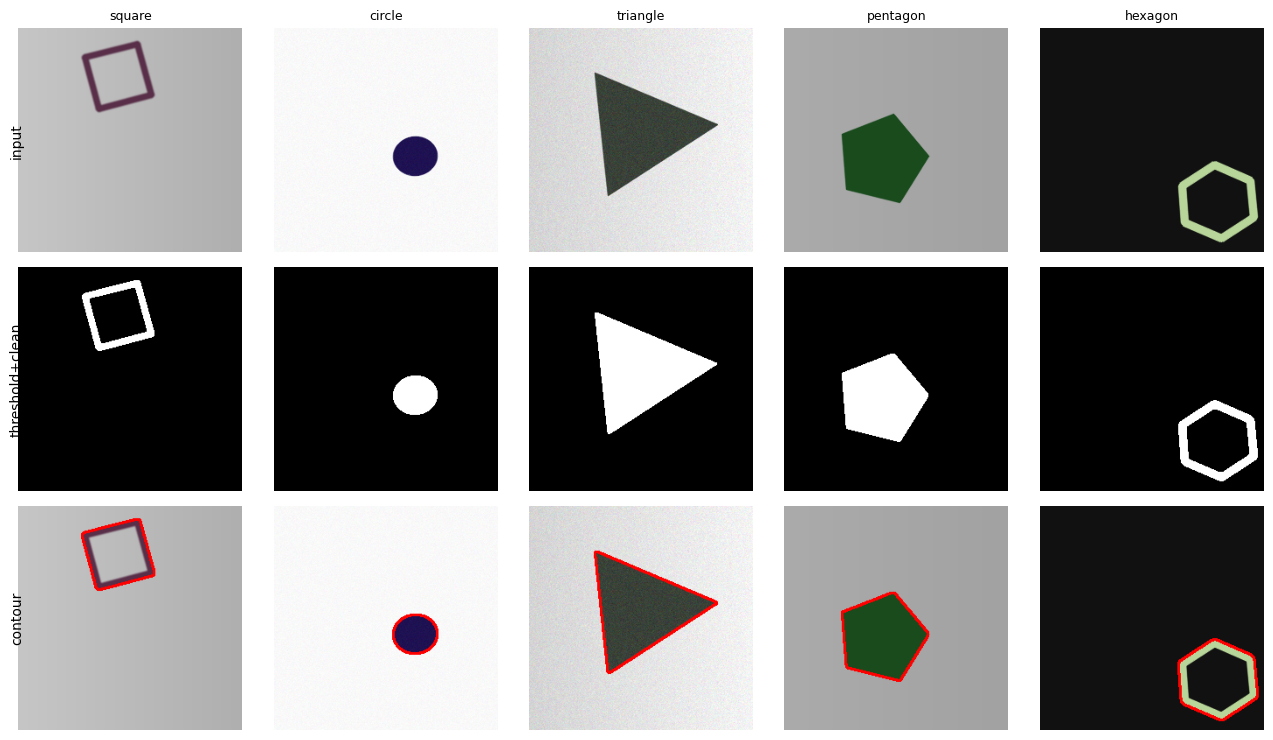

features: extracted for 800/800 images in 4s -> analysis_F_quick_s0/features.csv
segmentation succeeded for 800/800 images (100.0%)

mean of each feature per class:


cls,square,circle,triangle,pentagon,hexagon
circularity,0.729,0.890,0.582,0.786,0.826
solidity,0.981,0.990,0.975,0.984,0.985
extent,0.640,0.770,0.511,0.693,0.717
rect_fill,0.937,0.788,0.541,0.712,0.755
aspect,0.930,0.937,0.875,0.914,0.875
circ_ratio,0.632,0.902,0.448,0.733,0.787
ecc,0.371,0.369,0.409,0.368,0.369
v2,4.044,7.975,3.181,5.062,6.044
v4,4.019,7.588,3.019,4.975,5.988
radial_cv,0.112,0.034,0.218,0.079,0.056



feature discriminability (eta^2 from Kruskal-Wallis, ANOVA F, mutual information):


,feature,eta2_KW,anova_F,mutual_info
0,v4,0.966,2639.490,1.464
1,n_peaks,0.966,2038.971,1.478
2,v2,0.936,2207.031,1.376
3,circ_ratio,0.900,1600.927,1.374
4,rect_fill,0.887,1472.974,1.521
5,circularity,0.878,969.621,1.345
6,hu1,0.869,562.846,1.330
7,radial_cv,0.864,872.938,1.323
8,radial_ratio,0.860,731.552,1.244
9,extent,0.708,259.534,1.175


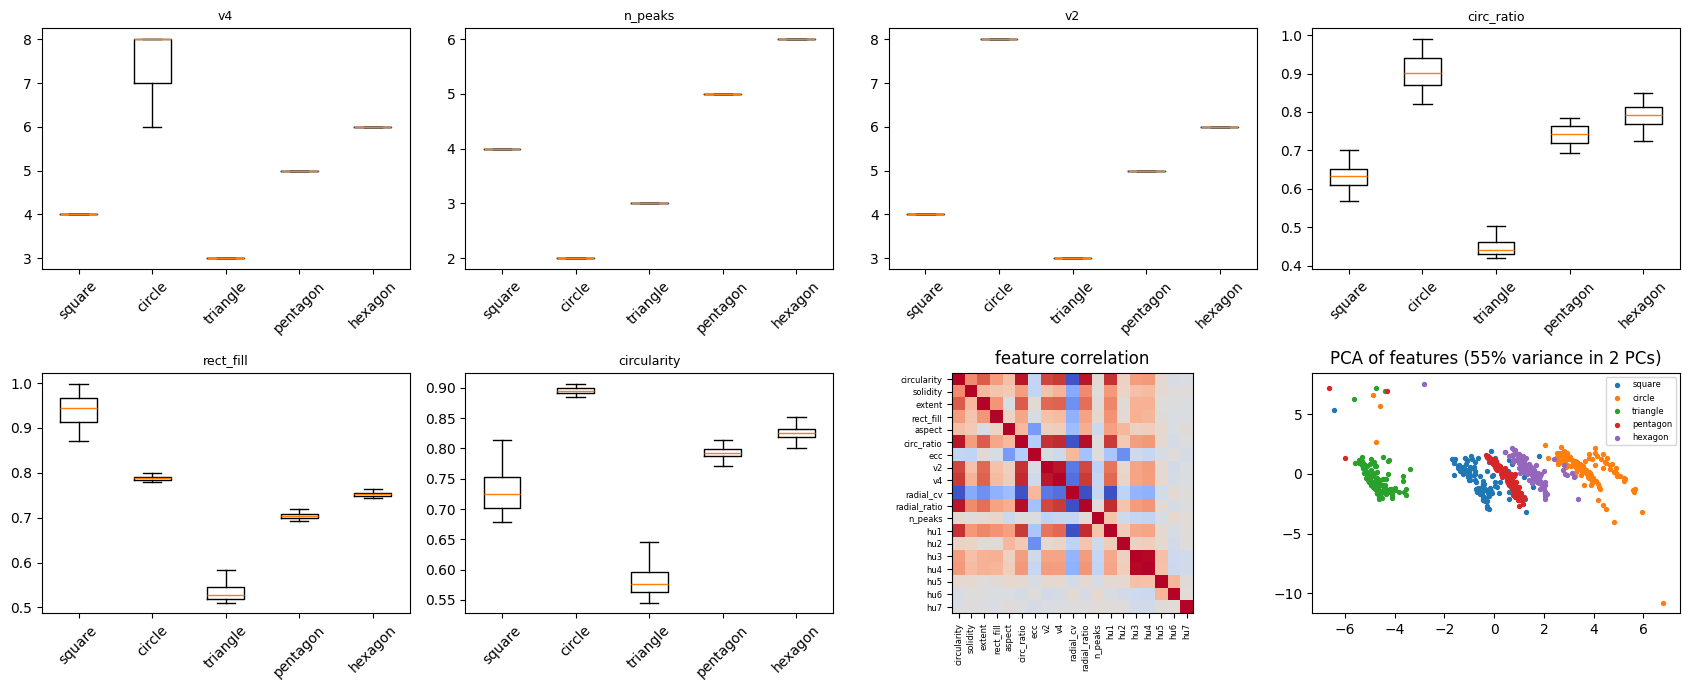

In [7]:
# ---------- EDA 2: segmentation check and feature analysis ----------
fig, ax = plt.subplots(3, NS, figsize=(2.6 * NS, 7.5))
for j, c in enumerate(SHAPES):
    p = meta[(meta.cls == c) & (meta.split == "train")].path.iloc[3]; im = read_rgb(p); th = segment(im); cs = contours_of(th); ov = im.copy(); cv2.drawContours(ov, cs, -1, (255, 0, 0), 2)
    ax[0, j].imshow(im); ax[1, j].imshow(th, cmap="gray"); ax[2, j].imshow(ov); ax[0, j].set_title(c, fontsize=9)
for a in ax.ravel(): a.axis("off")
ax[0, 0].text(-10, 128, "input", rotation=90, va="center"); ax[1, 0].text(-10, 128, "threshold+clean", rotation=90, va="center"); ax[2, 0].text(-10, 128, "contour", rotation=90, va="center")
plt.tight_layout(); plt.show()
feat = once("FT", KEY + (FID,), lambda: extract_all(meta)); ftr, fte = feat[feat.split == "train"].reset_index(drop=True), feat[feat.split == "test"].reset_index(drop=True)
cidx = {c: i for i, c in enumerate(SHAPES)}; ytr, yte = ftr.cls.map(cidx).values, fte.cls.map(cidx).values; Xtr, Xte = ftr[FEATS].values, fte[FEATS].values
print(f"segmentation succeeded for {len(feat)}/{len(meta)} images ({len(feat) / len(meta):.1%})"); print("\nmean of each feature per class:"); display(feat.groupby("cls")[FEATS].mean().loc[SHAPES].round(3).T)
rows = []; Fv, _ = f_classif(Xtr, ytr); MI = mutual_info_classif(Xtr, ytr, random_state=SEED)
for i, f in enumerate(FEATS):
    H = stats.kruskal(*[ftr[ftr.cls == c][f] for c in SHAPES]).statistic; rows.append(dict(feature=f, eta2_KW=(H - NS + 1) / (len(ftr) - NS), anova_F=Fv[i], mutual_info=MI[i]))
rank = pd.DataFrame(rows).sort_values("eta2_KW", ascending=False).reset_index(drop=True); print("\nfeature discriminability (eta^2 from Kruskal-Wallis, ANOVA F, mutual information):"); display(rank.round(3))
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for a, f in zip(ax.ravel()[:6], rank.feature[:6]): a.boxplot([ftr[ftr.cls == c][f] for c in SHAPES], showfliers=False); a.set_xticklabels(SHAPES); a.set_title(f, fontsize=9); a.tick_params(axis="x", rotation=45)
cm_ = ftr[FEATS].corr().values; ax[1, 2].imshow(cm_, cmap="coolwarm", vmin=-1, vmax=1); ax[1, 2].set_xticks(range(len(FEATS))); ax[1, 2].set_yticks(range(len(FEATS)))
ax[1, 2].set_xticklabels(FEATS, rotation=90, fontsize=6); ax[1, 2].set_yticklabels(FEATS, fontsize=6); ax[1, 2].set_title("feature correlation")
Z = PCA(2, random_state=SEED).fit(StandardScaler().fit(Xtr).transform(Xtr)); pc = Z.transform(StandardScaler().fit(Xtr).transform(Xtr))
for c in SHAPES: ax[1, 3].scatter(*pc[ytr == cidx[c]].T, s=8, label=c)
ax[1, 3].legend(fontsize=6); ax[1, 3].set_title(f"PCA of features ({Z.explained_variance_ratio_.sum():.0%} variance in 2 PCs)")
plt.tight_layout(); plt.savefig(f"{OUT_F}/eda_features.png", dpi=110); plt.show(); rank.to_csv(f"{OUT_F}/feature_ranking.csv", index=False)


## 3. Classification: rule-based baseline and ML models

  KNN: trained and saved analysis_F_quick_s0/model_KNN_dc5dec.joblib
  SVM: trained and saved analysis_F_quick_s0/model_SVM_dc5dec.joblib
  RandomForest: trained and saved analysis_F_quick_s0/model_RandomForest_dc5dec.joblib
  LogReg: trained and saved analysis_F_quick_s0/model_LogReg_dc5dec.joblib

TEST SET (200 images): accuracy, macro-F1 with 95% bootstrap CIs, kappa, MCC, one-vs-rest AUC


,accuracy,acc_CI,macro_F1,F1_CI,balanced_acc,kappa,MCC,AUC_ovr
model,,,,,,,,
Rule-based,0.955,"[0.922, 0.980]",0.955,"[0.920, 0.980]",0.955,0.944,0.944,NaN
KNN,0.960,"[0.927, 0.985]",0.960,"[0.927, 0.985]",0.960,0.950,0.951,0.996
SVM,0.980,"[0.960, 0.995]",0.980,"[0.959, 0.995]",0.980,0.975,0.975,0.999
RandomForest,0.980,"[0.955, 0.995]",0.980,"[0.957, 0.995]",0.980,0.975,0.975,1.000
LogReg,0.975,"[0.950, 0.993]",0.975,"[0.951, 0.993]",0.975,0.969,0.969,0.993


best ML model: SVM


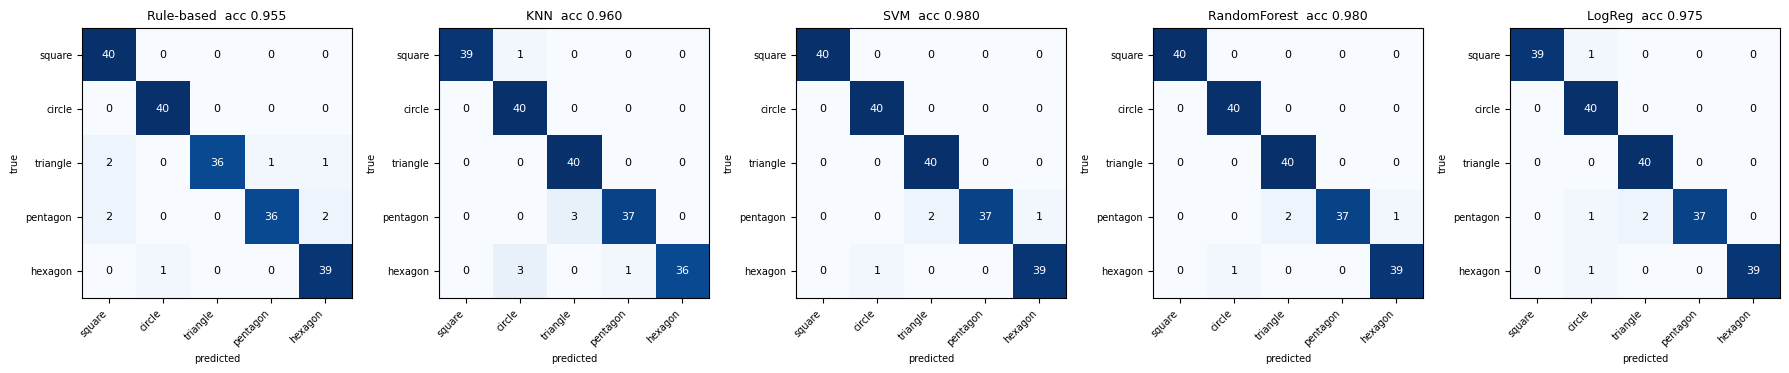


TP / FP / FN / TN per class for SVM:


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1
square,40,40,0,0,160,1.000,1.000,1.000,0.000,1.000
circle,40,40,1,0,159,0.976,1.000,0.994,0.006,0.988
triangle,40,40,2,0,158,0.952,1.000,0.988,0.012,0.976
pentagon,40,37,0,3,160,1.000,0.925,1.000,0.000,0.961
hexagon,40,39,1,1,159,0.975,0.975,0.994,0.006,0.975


TP / FP / FN / TN per class for the rule-based baseline:


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1
square,40,40,4,0,156,0.909,1.000,0.975,0.025,0.952
circle,40,40,1,0,159,0.976,1.000,0.994,0.006,0.988
triangle,40,36,0,4,160,1.000,0.900,1.000,0.000,0.947
pentagon,40,36,1,4,159,0.973,0.900,0.994,0.006,0.935
hexagon,40,39,3,1,157,0.929,0.975,0.981,0.019,0.951


In [8]:
# ---------- train once (saved with joblib) or load: rule-based baseline + KNN / SVM / Random Forest / Logistic regression ----------
RETRAIN = False                 # True = fit the ML models again (resets itself)
MODELS = {"KNN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(7)),
          "SVM": lambda: make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", probability=True, random_state=SEED)),
          "RandomForest": lambda: RandomForestClassifier(300, random_state=SEED, n_jobs=-1),
          "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=10, max_iter=3000))}
def get_model(name):
    f = f"{OUT_F}/model_{name}_{FID}.joblib"
    if os.path.exists(f) and not RETRAIN: print(f"  {name}: loaded {f} (no training)"); return joblib.load(f)
    m = MODELS[name](); m.fit(Xtr, ytr); joblib.dump(m, f); print(f"  {name}: trained and saved {f}"); return m
if RETRAIN: _mem.pop("MD", None)
MD = once("MD", KEY + (FID,), lambda: {n: get_model(n) for n in MODELS}); RETRAIN = False
PRED = {"Rule-based": (np.array([cidx[c] for c in rule_predict(fte)]), None)}
for n, m in MD.items(): PRED[n] = (m.predict(Xte), m.predict_proba(Xte))
rng = np.random.default_rng(SEED); rows = []
for n, (p, pr) in PRED.items():
    a_ci, f_ci = boot_ci(yte, p, rng, min(BOOT, 1000)); cmx = cm_np(yte, p)
    rows.append(dict(model=n, accuracy=np.trace(cmx) / cmx.sum(), acc_CI=f"[{a_ci[0]:.3f}, {a_ci[1]:.3f}]", macro_F1=macro_f1_cm(cmx), F1_CI=f"[{f_ci[0]:.3f}, {f_ci[1]:.3f}]",
                     balanced_acc=balanced_accuracy_score(yte, p), kappa=cohen_kappa_score(yte, p), MCC=matthews_corrcoef(yte, p),
                     AUC_ovr=roc_auc_score(yte, pr, multi_class="ovr") if pr is not None else np.nan))
res = pd.DataFrame(rows).set_index("model"); print(f"\nTEST SET ({len(yte)} images): accuracy, macro-F1 with 95% bootstrap CIs, kappa, MCC, one-vs-rest AUC"); display(res.round(3)); res.to_csv(f"{OUT_F}/model_comparison.csv")
BEST = res.drop(index="Rule-based").macro_F1.idxmax(); print("best ML model:", BEST)
fig, ax = plt.subplots(1, len(PRED), figsize=(3.6 * len(PRED), 3.6))
for a, (n, (p, _)) in zip(ax, PRED.items()): plot_cm(a, cm_np(yte, p), SHAPES, f"{n}  acc {np.mean(p == yte):.3f}")
plt.tight_layout(); plt.savefig(f"{OUT_F}/confusion_matrices.png", dpi=110); plt.show()
print(f"\nTP / FP / FN / TN per class for {BEST}:"); tt = tpfp_table(yte, PRED[BEST][0]); display(tt.round(3)); tt.to_csv(f"{OUT_F}/tpfp_{BEST}.csv")
print("TP / FP / FN / TN per class for the rule-based baseline:"); display(tpfp_table(yte, PRED["Rule-based"][0]).round(3))


## 4. ROC / PR, cross-validation, learning curve, importance, regression coefficients

5-fold cross-validated macro-F1 (train): {'KNN': '0.965 +/- 0.010', 'SVM': '0.985 +/- 0.011', 'RandomForest': '0.985 +/- 0.008', 'LogReg': '0.980 +/- 0.007'}


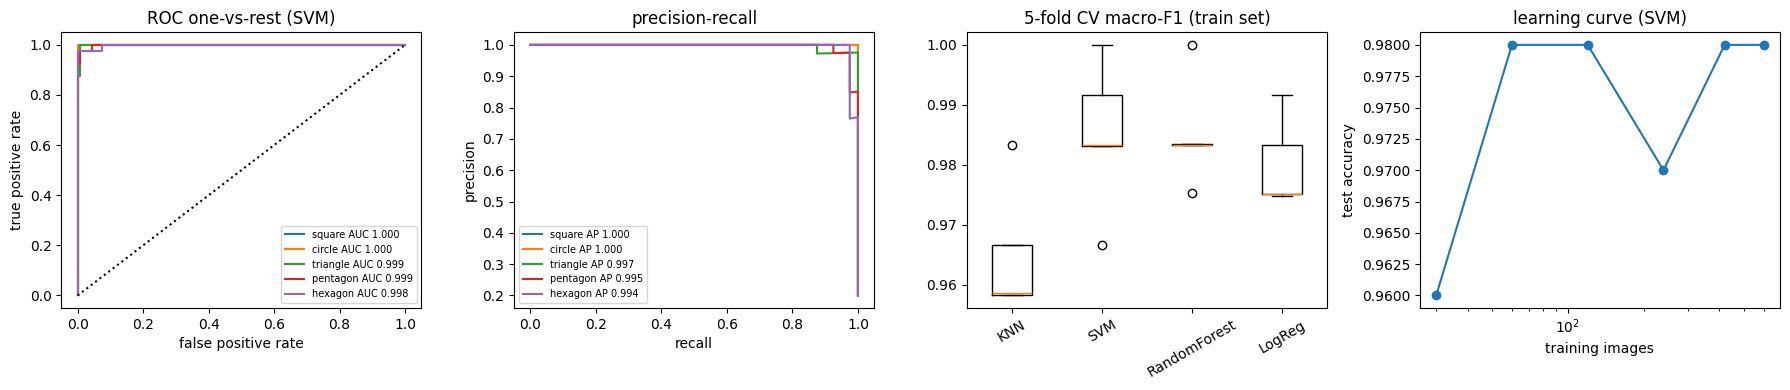

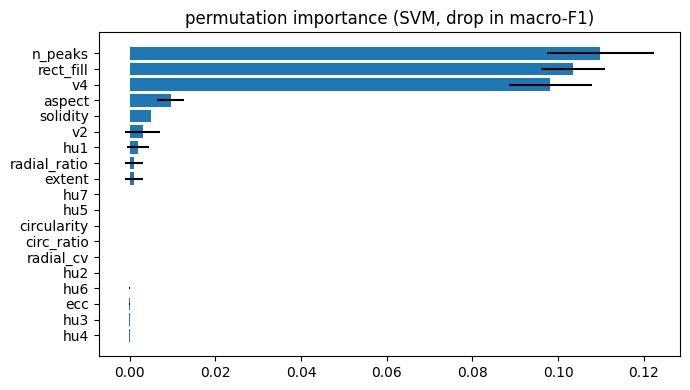

multinomial logistic-regression coefficients (standardised features; + = pushes towards that class):


,circularity,solidity,extent,rect_fill,aspect,circ_ratio,ecc,v2,v4,radial_cv,radial_ratio,n_peaks,hu1,hu2,hu3,hu4,hu5,hu6,hu7
square,-0.57,-1.55,-0.71,4.58,0.52,-1.20,0.70,-1.22,-0.11,-0.33,1.32,-1.48,1.96,0.30,0.49,0.37,-0.16,-0.15,-0.00
circle,-0.61,0.14,1.73,0.80,1.06,2.42,0.98,1.07,1.98,0.00,-1.45,-3.02,-0.17,-0.13,0.76,0.56,1.35,-0.40,-0.34
triangle,0.74,0.74,-2.26,-3.62,0.33,-1.93,-0.59,-0.36,-2.76,1.78,-0.95,-0.06,-2.03,0.47,-1.42,-1.16,-1.21,0.37,-0.93
pentagon,-1.09,0.08,0.31,-3.45,-0.14,0.73,-1.24,-1.15,-1.80,-0.25,-0.02,-0.01,-0.57,-0.76,-0.37,-0.90,-0.14,0.03,0.60
hexagon,1.53,0.59,0.93,1.69,-1.77,-0.02,0.14,1.66,2.69,-1.20,1.11,4.57,0.81,0.12,0.54,1.13,0.16,0.15,0.67


In [9]:
# ---------- ROC / precision-recall (one-vs-rest), cross-validation, learning curve, feature importance ----------
pb = PRED[BEST][1]; fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for k, c in enumerate(SHAPES):
    fpr, tpr, _ = roc_curve(yte == k, pb[:, k]); ax[0].plot(fpr, tpr, label=f"{c} AUC {roc_auc_score(yte == k, pb[:, k]):.3f}")
    pr_, rc_, _ = precision_recall_curve(yte == k, pb[:, k]); ax[1].plot(rc_, pr_, label=f"{c} AP {average_precision_score(yte == k, pb[:, k]):.3f}")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title(f"ROC one-vs-rest ({BEST})"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].legend(fontsize=7)
ax[1].set_title("precision-recall"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend(fontsize=7)
cvf = f"{OUT_F}/cv_{FID}.json"
if os.path.exists(cvf): cv = json.load(open(cvf)); print("cross-validation: loaded", cvf)
else:
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED); cv = {n: cross_val_score(clone(MODELS[n]()), Xtr, ytr, cv=skf, scoring="f1_macro").tolist() for n in MODELS}; json.dump(cv, open(cvf, "w"))
ax[2].boxplot(list(cv.values())); ax[2].set_xticklabels(list(cv)); ax[2].set_title("5-fold CV macro-F1 (train set)"); ax[2].tick_params(axis="x", rotation=30)
print("5-fold cross-validated macro-F1 (train):", {n: f"{np.mean(v):.3f} +/- {np.std(v):.3f}" for n, v in cv.items()})
lcf = f"{OUT_F}/learning_curve_{FID}.json"
if os.path.exists(lcf): lc = json.load(open(lcf))
else:
    lc = []; r_ = np.random.default_rng(SEED)
    for fr in (.05, .1, .2, .4, .7, 1.):
        idx = r_.permutation(len(ytr))[:max(int(fr * len(ytr)), NS * 3)]; m = clone(MODELS[BEST]()).fit(Xtr[idx], ytr[idx]); lc.append((len(idx), float(np.mean(m.predict(Xte) == yte))))
    json.dump(lc, open(lcf, "w"))
ax[3].plot(*zip(*lc), "o-"); ax[3].set_xscale("log"); ax[3].set_xlabel("training images"); ax[3].set_ylabel("test accuracy"); ax[3].set_title(f"learning curve ({BEST})")
plt.tight_layout(); plt.savefig(f"{OUT_F}/roc_pr_cv_learning.png", dpi=110); plt.show()
pi = permutation_importance(MD[BEST], Xte, yte, n_repeats=5 if QUICK else 15, random_state=SEED, scoring="f1_macro"); order = np.argsort(pi.importances_mean)[::-1]
plt.figure(figsize=(7, 4)); plt.barh([FEATS[i] for i in order][::-1], pi.importances_mean[order][::-1], xerr=pi.importances_std[order][::-1]); plt.title(f"permutation importance ({BEST}, drop in macro-F1)"); plt.tight_layout(); plt.show()
lr = MD["LogReg"][-1]; coef = pd.DataFrame(lr.coef_, index=SHAPES, columns=FEATS); print("multinomial logistic-regression coefficients (standardised features; + = pushes towards that class):"); display(coef.round(2))


## 5. Subgroup analysis and failure cases


Rule-based: accuracy by subgroup (chi-square p for 'accuracy depends on this factor')
  bg            p = 0.192 | gradient: 0.90 (n=51) | noisy: 0.96 (n=52) | plain_dark: 0.98 (n=47) | plain_light: 0.98 (n=50)
  filled        p = 0.468 | False: 0.94 (n=77) | True: 0.97 (n=123)
  size_bin      p = 0.000 | small: 0.84 (n=50) | mid-small: 0.98 (n=50) | mid-large: 1.00 (n=50) | large: 1.00 (n=50)
  rot_bin       p = 0.941 | (-0.001, 22.5]: 0.96 (n=50) | (22.5, 45.0]: 0.95 (n=40) | (45.0, 67.5]: 0.97 (n=58) | (67.5, 90.0]: 0.94 (n=52)
  contrast_bin  p = 0.117 | low: 0.90 (n=50) | mid-low: 0.96 (n=50) | mid-high: 0.96 (n=51) | high: 1.00 (n=49)

SVM: accuracy by subgroup (chi-square p for 'accuracy depends on this factor')
  bg            p = 0.008 | gradient: 0.92 (n=51) | noisy: 1.00 (n=52) | plain_dark: 1.00 (n=47) | plain_light: 1.00 (n=50)
  filled        p = 0.319 | False: 0.96 (n=77) | True: 0.99 (n=123)
  size_bin      p = 0.106 | small: 0.94 (n=50) | mid-small: 0.98 (n=50) | mid-l

,radius,contrast,noise,blur,filled,bg_noisy,bg_plain_dark,bg_plain_light
odds_ratio,7.36,1.85,1.8,1.14,1.44,1.39,1.44,1.47


SVM: only 4 errors, too few for a logistic regression on difficulty factors


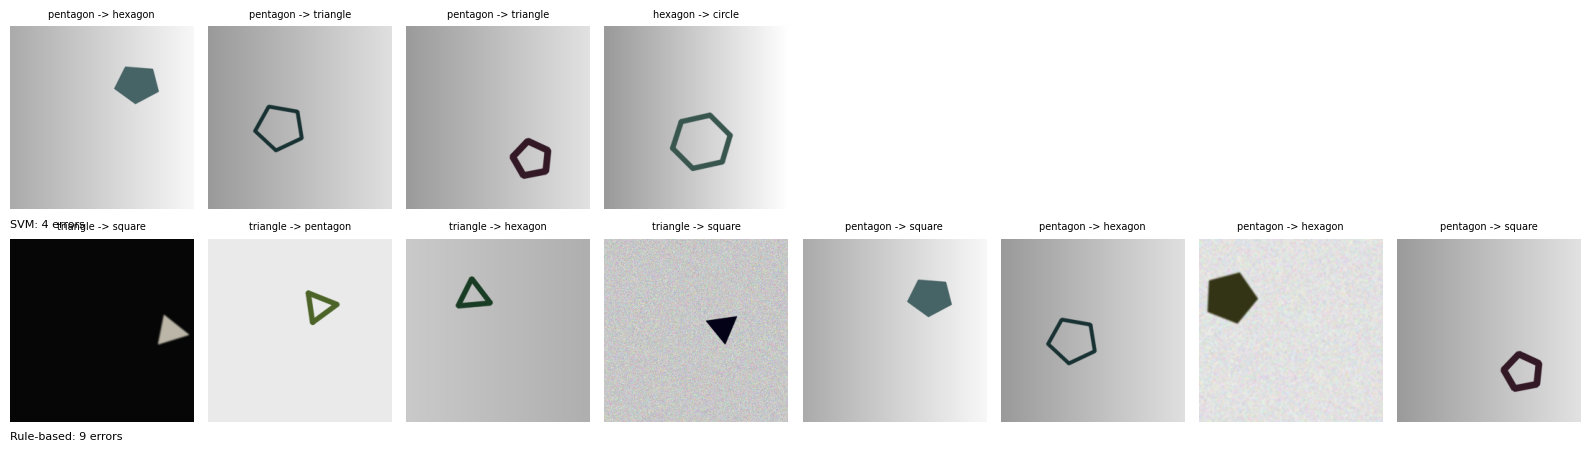

In [10]:
# ---------- subgroup analysis: where does it fail? (accuracy by background, fill, rotation, size, contrast; logistic regression on difficulty) ----------
def subgroup(pred, name):
    d = fte.copy(); d["correct"] = (pred == yte).astype(int); d["size_bin"] = pd.qcut(d.radius, 4, labels=["small", "mid-small", "mid-large", "large"]); d["rot_bin"] = pd.cut(d.rot_deg % 90, [0, 22.5, 45, 67.5, 90], include_lowest=True)
    d["contrast_bin"] = pd.qcut(d.contrast, 4, labels=["low", "mid-low", "mid-high", "high"]); out = {}
    for g in ("bg", "filled", "size_bin", "rot_bin", "contrast_bin"):
        t = d.groupby(g, observed=True).correct.agg(["mean", "sum", "count"]); ct = pd.crosstab(d[g], d.correct)
        p = stats.chi2_contingency(ct)[1] if ct.shape[1] == 2 and ct.shape[0] > 1 else np.nan; out[g] = (t, p)
    print(f"\n{name}: accuracy by subgroup (chi-square p for 'accuracy depends on this factor')")
    for g, (t, p) in out.items(): print(f"  {g:13s} p = {p:.3f} | " + " | ".join(f"{i}: {r['mean']:.2f} (n={int(r['count'])})" for i, r in t.iterrows()))
    return d
d_rule = subgroup(PRED["Rule-based"][0], "Rule-based"); d_best = subgroup(PRED[BEST][0], BEST)
def difficulty_regression(d, name):
    X = pd.get_dummies(d[["radius", "contrast", "noise", "blur", "filled", "bg"]], columns=["bg"], drop_first=True).astype(float); y = d.correct.values
    if (1 - y).sum() < 8: print(f"{name}: only {int((1 - y).sum())} errors, too few for a logistic regression on difficulty factors"); return
    Z = (X - X.mean()) / X.std().replace(0, 1); m = LogisticRegression(C=1., max_iter=2000).fit(Z, y)
    print(f"\n{name}: logistic regression of 'correct' on standardised difficulty factors (odds ratio per +1 SD; <1 makes errors more likely)")
    display(pd.DataFrame(dict(odds_ratio=np.exp(m.coef_[0])), index=X.columns).round(2).T)
difficulty_regression(d_rule, "Rule-based"); difficulty_regression(d_best, BEST)
mis = np.flatnonzero(PRED[BEST][0] != yte); misr = np.flatnonzero(PRED["Rule-based"][0] != yte); fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for r_, (ids, nm, pp) in enumerate(((mis, BEST, PRED[BEST][0]), (misr, "Rule-based", PRED["Rule-based"][0]))):
    for j in range(8):
        ax[r_, j].axis("off")
        if j < len(ids): i = ids[j]; ax[r_, j].imshow(read_rgb(fte.path[i])); ax[r_, j].set_title(f"{fte.cls[i]} -> {SHAPES[pp[i]]}", fontsize=7)
    ax[r_, 0].text(0, -.1, f"{nm}: {len(ids)} errors", transform=ax[r_, 0].transAxes, fontsize=8)
plt.tight_layout(); plt.show()


## 6. Robustness (regression of accuracy on perturbation strength)

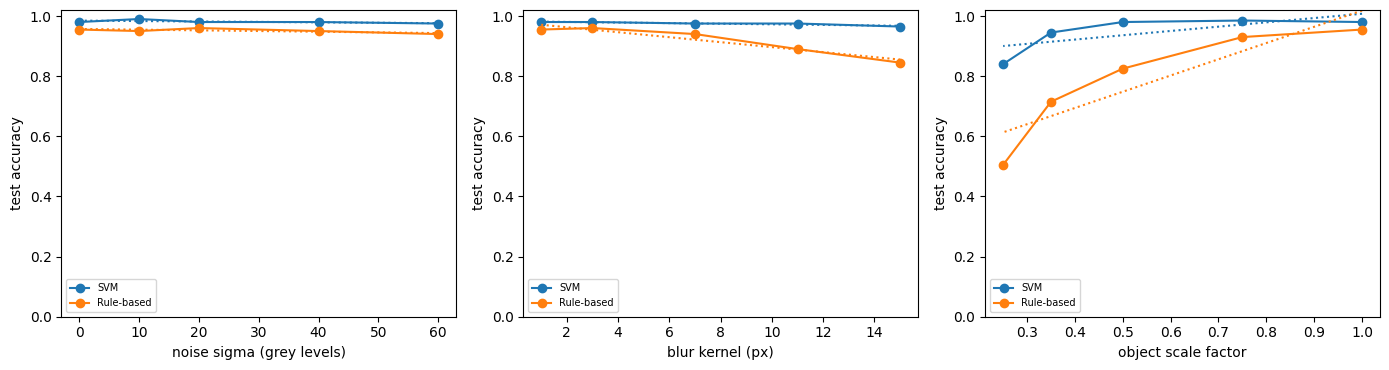

linear regression of accuracy on perturbation strength (dotted lines):


,perturbation,model,slope_per_unit,R2,p,acc_clean,acc_worst
0,noise,SVM,-0.0001,0.3912,0.2592,0.980,0.975
1,noise,Rule-based,-0.0002,0.5504,0.1512,0.955,0.940
2,blur,SVM,-0.0010,0.8587,0.0236,0.980,0.965
3,blur,Rule-based,-0.0083,0.9239,0.0091,0.955,0.845
4,scale,SVM,0.1432,0.5073,0.1771,0.980,0.840
5,scale,Rule-based,0.5399,0.8066,0.0384,0.955,0.505


In [11]:
# ---------- robustness sweep: noise, blur, shrinking. Regression of accuracy on perturbation strength ----------
def perturb(img, kind, lv, rng):
    if kind == "noise": return np.clip(img + rng.normal(0, lv, img.shape), 0, 255).astype(np.uint8)
    if kind == "blur": return img if lv <= 1 else cv2.GaussianBlur(img, (int(lv), int(lv)), 0)
    s = max(int(SIZE * lv), 8); sm = cv2.resize(img, (s, s), interpolation=cv2.INTER_AREA); bgc = np.median(np.concatenate([img[0], img[-1]]), axis=0).astype(np.uint8)
    out = np.full_like(img, bgc); o = (SIZE - s) // 2; out[o:o + s, o:o + s] = sm; return out
SWEEP = {"noise": [0, 10, 20, 40, 60], "blur": [1, 3, 7, 11, 15], "scale": [1., .75, .5, .35, .25]}
def robust_build():
    res = {}
    for kind, lvls in SWEEP.items():
        for lv in lvls:
            rng = np.random.default_rng(SEED); fs, ys, ps = [], [], []
            for i, p in enumerate(fte.path):
                ft = image_features(perturb(read_rgb(p), kind, lv, rng))
                if ft is None: ys.append(yte[i]); ps.append(-1); fs.append(None); continue
                ys.append(yte[i]); fs.append([ft[k] for k in FEATS])
            ok = [f is not None for f in fs]; pm = MD[BEST].predict(np.array([f for f in fs if f is not None])); pr = np.full(len(fs), -1); pr[np.array(ok)] = pm
            rl = rule_predict(pd.DataFrame([dict(zip(FEATS, f)) for f in fs if f is not None])); prr = np.full(len(fs), -1); prr[np.array(ok)] = [cidx[c] for c in rl]
            res[f"{kind}|{lv}"] = dict(ml=float((pr == np.array(ys)).mean()), rule=float((prr == np.array(ys)).mean()), segmented=float(np.mean(ok)))
    return res
def robust_cached():
    f = f"{OUT_F}/robust_{FID}.json"
    if os.path.exists(f): print("robustness sweep: loaded", f); return json.load(open(f))
    r = robust_build(); json.dump(r, open(f, "w")); return r
rb = once("RB", KEY + (FID, BEST), robust_cached)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8)); lines = []
for a, (kind, lvls) in zip(ax, SWEEP.items()):
    for key, lab in (("ml", BEST), ("rule", "Rule-based")):
        y_ = [rb[f"{kind}|{l}"][key] for l in lvls]; lg = stats.linregress(lvls, y_); a.plot(lvls, y_, "o-", label=lab); a.plot(lvls, lg.intercept + lg.slope * np.array(lvls), ":", c=a.lines[-1].get_color())
        lines.append(dict(perturbation=kind, model=lab, slope_per_unit=lg.slope, R2=lg.rvalue ** 2, p=lg.pvalue, acc_clean=y_[0], acc_worst=y_[-1]))
    a.set_xlabel({"noise": "noise sigma (grey levels)", "blur": "blur kernel (px)", "scale": "object scale factor"}[kind]); a.set_ylabel("test accuracy"); a.legend(fontsize=7); a.set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig(f"{OUT_F}/robustness.png", dpi=110); plt.show(); print("linear regression of accuracy on perturbation strength (dotted lines):"); display(pd.DataFrame(lines).round(4))


## 7. Object counting, overlapping shapes, multi-object scenes

COUNTING on 40 scenes (143 true objects): exact-count rate 70.0% | MAE 0.72 | bias -0.72 (negative = merged/missed)
DETECTION (centroid matching): TP 113 | FP 1 | FN 30 | precision 0.991 | recall 0.790 | F1 0.879
CLASSIFICATION of matched objects: accuracy 0.876 | END-TO-END true positives (detected AND right class): 99 of 143 (69.2%)
   matched-object accuracy: separate shapes 0.989 | overlapping shapes 0.350 (touching same-colour shapes merge into one contour)

by overlap (extension: overlapping shapes):


,scenes,exact,MAE,bias,det_precision,det_recall
False,28.0,1.0,0.000,0.000,1.000,1.0
True,12.0,0.0,2.417,-2.417,0.952,0.4


by number of objects (extension: multi-object scenes):


,scenes,exact,MAE,bias,det_precision,det_recall
1,5.0,1.000,0.000,0.000,1.000,1.000
2,8.0,0.750,0.250,-0.250,1.000,0.875
3,6.0,0.667,0.500,-0.500,1.000,0.833
4,7.0,0.857,0.286,-0.286,1.000,0.929
5,8.0,0.250,2.250,-2.250,1.000,0.550
6,6.0,0.833,0.667,-0.667,0.969,0.861



regression predicted = a + b*true: slope 0.709 (ideal 1), intercept 0.314 (ideal 0), R2 0.506
regression |count error| ~ true_count + overlap_pairs: coefficients [0.003 0.719] (per object / per overlapping pair), R2 0.970


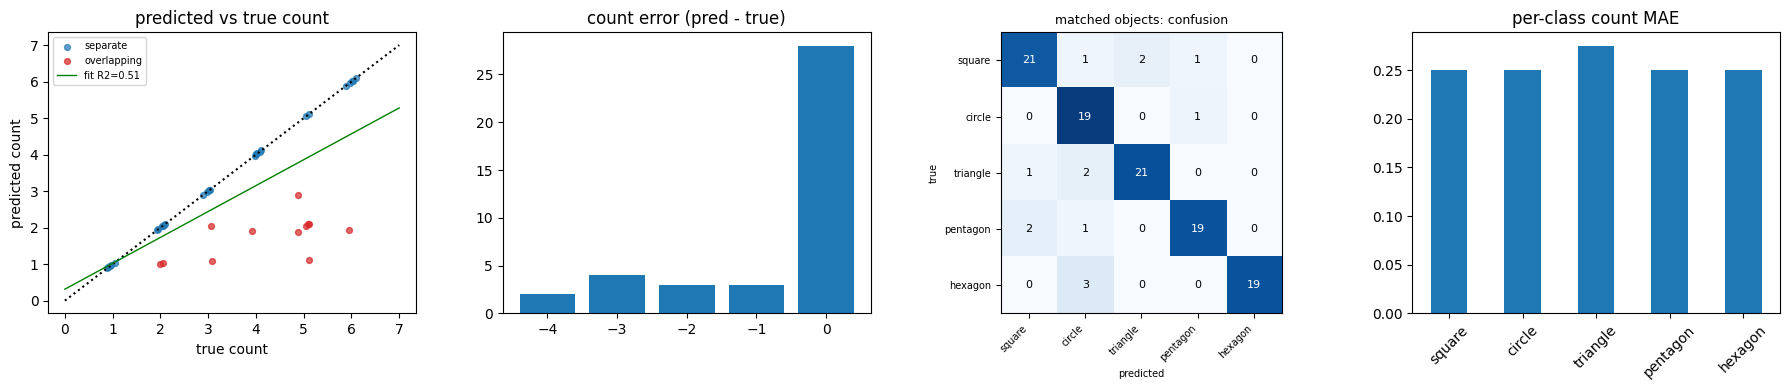

In [12]:
# ---------- object counting: detect every contour, classify each, compare with the true scene content ----------
def analyse_scene(img, model):
    cs = contours_of(segment(img), MIN_AREA); objs = []
    for c in cs:
        f = contour_features(c)
        if f is None: continue
        x, y, w, h = cv2.boundingRect(c); objs.append(dict(cx=f["cx"], cy=f["cy"], box=(x, y, w, h), feats=[f[k] for k in FEATS]))
    if objs: lab = model.predict(np.array([o["feats"] for o in objs])); [o.update(cls=SHAPES[int(l)]) for o, l in zip(objs, lab)]
    return objs

def count_build():
    srows, orows = [], []
    for _, s in scenes.iterrows():
        gt = scene_gt[str(int(s.scene))]; pred = analyse_scene(read_rgb(s.path), MD[BEST]); n_g, n_p = len(gt), len(pred)
        if gt and pred:
            D = np.array([[np.hypot(g["cx"] - p["cx"], g["cy"] - p["cy"]) for p in pred] for g in gt]); ri, ci = linear_sum_assignment(D)
            m = [(i, j) for i, j in zip(ri, ci) if D[i, j] < max(.7 * gt[i]["r"], 12)]
        else: m = []
        tp = len(m); corr = sum(gt[i]["cls"] == pred[j]["cls"] for i, j in m)
        for i, j in m: orows.append(dict(scene=int(s.scene), true=gt[i]["cls"], pred=pred[j]["cls"], overlap=bool(s.overlap)))
        row = dict(scene=int(s.scene), true_count=n_g, pred_count=n_p, overlap=bool(s.overlap), overlap_pairs=int(s.overlap_pairs), bg=s.bg, det_TP=tp, det_FP=n_p - tp, det_FN=n_g - tp, cls_correct=corr)
        for c in SHAPES: row[f"true_{c}"] = sum(g["cls"] == c for g in gt); row[f"pred_{c}"] = sum(p["cls"] == c for p in pred)
        srows.append(row)
    sc, ob = pd.DataFrame(srows), pd.DataFrame(orows); sc.to_csv(f"{OUT_F}/scene_results.csv", index=False); ob.to_csv(f"{OUT_F}/matched_objects.csv", index=False); return sc, ob
RECOUNT = False                 # True = recompute the counting results (resets itself)
def count_cached():
    f = f"{OUT_F}/scene_results.csv"
    if os.path.exists(f) and not RECOUNT: print("counting: loaded", f); return pd.read_csv(f), pd.read_csv(f"{OUT_F}/matched_objects.csv")
    return count_build()
if RECOUNT: _mem.pop("CNT", None)
SC, OB = once("CNT", KEY + (FID, BEST), count_cached); RECOUNT = False
err = SC.pred_count - SC.true_count
print(f"COUNTING on {len(SC)} scenes ({int(SC.true_count.sum())} true objects): exact-count rate {np.mean(err == 0):.1%} | MAE {np.abs(err).mean():.2f} | bias {err.mean():+.2f} (negative = merged/missed)")
TP_, FP_, FN_ = SC.det_TP.sum(), SC.det_FP.sum(), SC.det_FN.sum(); pr_, rc_ = TP_ / max(TP_ + FP_, 1), TP_ / max(TP_ + FN_, 1)
print(f"DETECTION (centroid matching): TP {TP_} | FP {FP_} | FN {FN_} | precision {pr_:.3f} | recall {rc_:.3f} | F1 {2 * pr_ * rc_ / max(pr_ + rc_, 1e-9):.3f}")
print(f"CLASSIFICATION of matched objects: accuracy {SC.cls_correct.sum() / max(TP_, 1):.3f} | END-TO-END true positives (detected AND right class): {SC.cls_correct.sum()} of {int(SC.true_count.sum())} ({SC.cls_correct.sum() / SC.true_count.sum():.1%})")
print(f"   matched-object accuracy: separate shapes {np.mean((OB.true == OB.pred)[~OB.overlap.astype(bool)]):.3f} | overlapping shapes {np.mean((OB.true == OB.pred)[OB.overlap.astype(bool)]):.3f} (touching same-colour shapes merge into one contour)")
def summarize(d): return pd.Series(dict(scenes=len(d), exact=np.mean(d.pred_count == d.true_count), MAE=np.abs(d.pred_count - d.true_count).mean(), bias=(d.pred_count - d.true_count).mean(),
                                          det_precision=d.det_TP.sum() / max(d.det_TP.sum() + d.det_FP.sum(), 1), det_recall=d.det_TP.sum() / max(d.det_TP.sum() + d.det_FN.sum(), 1)))
print("\nby overlap (extension: overlapping shapes):"); display(pd.DataFrame({k: summarize(d) for k, d in SC.groupby("overlap")}).T.round(3))
print("by number of objects (extension: multi-object scenes):"); display(pd.DataFrame({k: summarize(d) for k, d in SC.groupby("true_count")}).T.round(3))
lg = stats.linregress(SC.true_count, SC.pred_count); print(f"\nregression predicted = a + b*true: slope {lg.slope:.3f} (ideal 1), intercept {lg.intercept:.3f} (ideal 0), R2 {lg.rvalue ** 2:.3f}")
X_ = np.c_[SC.true_count, SC.overlap_pairs]; lm = LinearRegression().fit(X_, np.abs(err)); print(f"regression |count error| ~ true_count + overlap_pairs: coefficients {lm.coef_.round(3)} (per object / per overlapping pair), R2 {lm.score(X_, np.abs(err)):.3f}")
fig, ax = plt.subplots(1, 4, figsize=(18, 4)); j = np.random.default_rng(0).uniform(-.12, .12, len(SC))
for ov, col in ((False, "tab:blue"), (True, "tab:red")): m_ = SC.overlap == ov; ax[0].scatter(SC.true_count[m_] + j[m_], SC.pred_count[m_] + j[m_], c=col, s=18, alpha=.7, label="overlapping" if ov else "separate")
mx = SC.true_count.max() + 1; ax[0].plot([0, mx], [0, mx], "k:"); ax[0].plot([0, mx], lg.intercept + lg.slope * np.array([0, mx]), "g-", lw=1, label=f"fit R2={lg.rvalue ** 2:.2f}"); ax[0].set_xlabel("true count"); ax[0].set_ylabel("predicted count"); ax[0].legend(fontsize=7); ax[0].set_title("predicted vs true count")
ax[1].hist(err, bins=np.arange(err.min() - .5, err.max() + 1.5), rwidth=.8); ax[1].set_title("count error (pred - true)")
cmo = cm_np([SHAPES.index(t) for t in OB.true], [SHAPES.index(p) for p in OB.pred]); plot_cm(ax[2], cmo, SHAPES, "matched objects: confusion")
pcm = pd.DataFrame({c: [np.abs(SC[f"pred_{c}"] - SC[f"true_{c}"]).mean()] for c in SHAPES}).T[0]; pcm.plot.bar(ax=ax[3], title="per-class count MAE"); ax[3].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{OUT_F}/counting_analysis.png", dpi=110); plt.show()


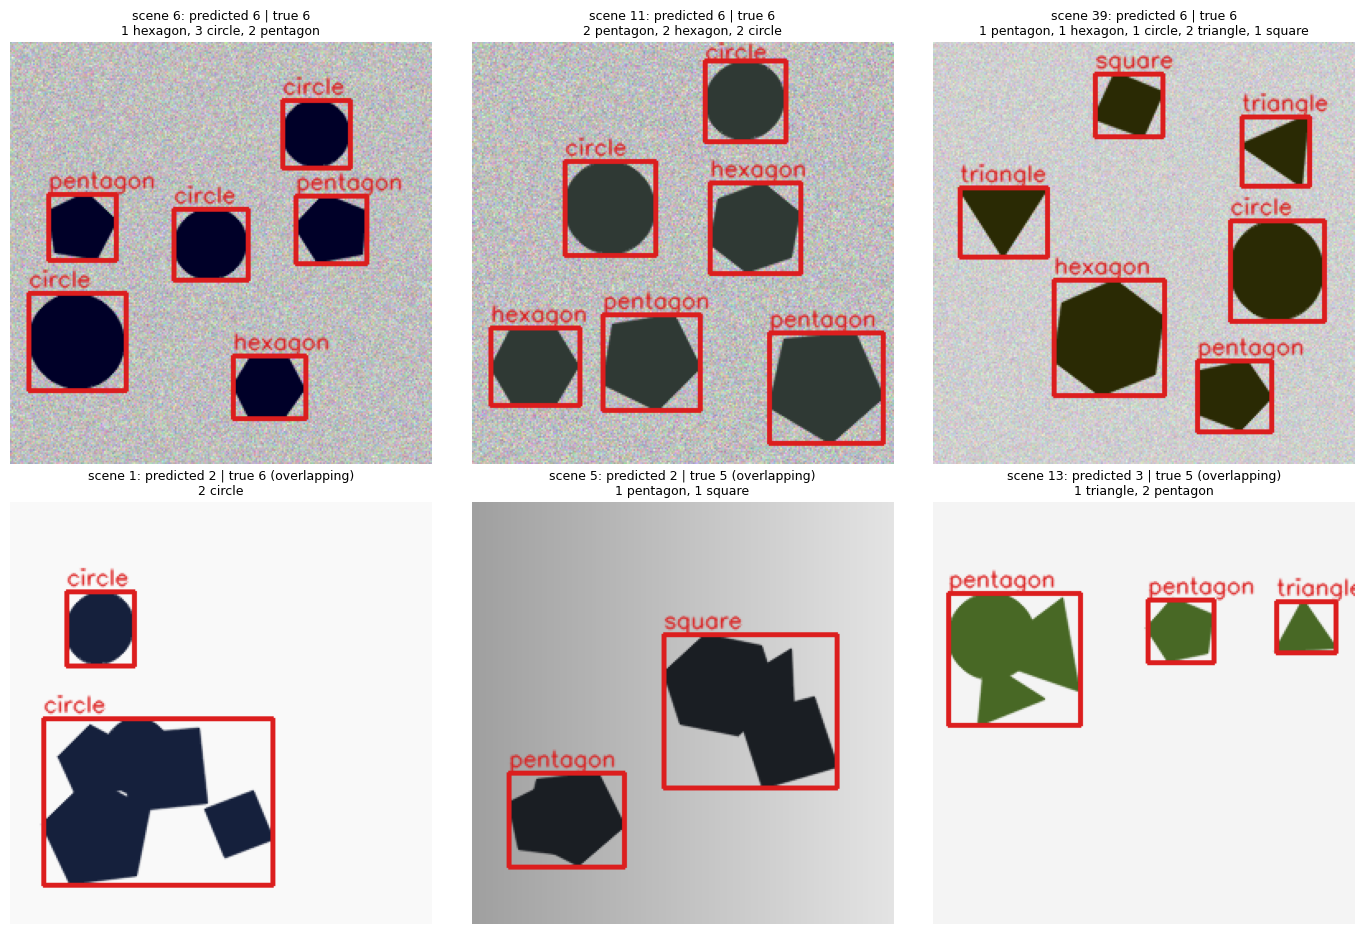

saved analysis_F_quick_s0/counting_demo.png and one PNG per scene in analysis_F_quick_s0


In [13]:
# ---------- object-counting demo images (saved as PNG for the repository / report) ----------
def annotate(path, model):
    img = read_rgb(path); objs = analyse_scene(img, model); out = img.copy(); cnt = {}
    for o in objs:
        x, y, w, h = o["box"]; cv2.rectangle(out, (x, y), (x + w, y + h), (220, 30, 30), 2); cv2.putText(out, o["cls"], (x, max(y - 4, 10)), cv2.FONT_HERSHEY_SIMPLEX, .45, (220, 30, 30), 1, cv2.LINE_AA); cnt[o["cls"]] = cnt.get(o["cls"], 0) + 1
    return out, len(objs), cnt
pick_ids = list(SC[~SC.overlap].sort_values("true_count", ascending=False).head(3).scene) + list(SC[SC.overlap].sort_values("true_count", ascending=False).head(3).scene)   # busiest separate scenes, then busiest overlapping ones
fig, ax = plt.subplots(2, 3, figsize=(14, 9.4))
for a, sid in zip(ax.ravel(), pick_ids):
    s = scenes[scenes.scene == sid].iloc[0]; out, n, cnt = annotate(s.path, MD[BEST]); a.imshow(out); a.axis("off")
    a.set_title(f"scene {sid}: predicted {n} | true {int(s.n_objects)}" + (" (overlapping)" if s.overlap else "") + "\n" + ", ".join(f"{v} {k}" for k, v in cnt.items()), fontsize=9)
    cv2.imwrite(f"{OUT_F}/counting_demo_scene{sid}.png", cv2.cvtColor(out, cv2.COLOR_RGB2BGR))
plt.tight_layout(); plt.savefig(f"{OUT_F}/counting_demo.png", dpi=120); plt.show(); print("saved", f"{OUT_F}/counting_demo.png", "and one PNG per scene in", OUT_F)


## 8. Link to the prosthetic pipeline (inputs from modules B/C/E)

pipeline images: {'train': (240, 256, 256), 'val': (80, 256, 256), 'test': (120, 256, 256)} | classes ['circle', 'square', 'triangle', 'line']
classical segmentation worked on 100.0% of the pipeline images

EDA of the pipeline dataset: mean ink coverage and shape features per class


,ink,circularity,solidity,extent,rect_fill,aspect,circ_ratio,ecc,v2
cls,,,,,,,,,
circle,0.023,0.387,0.466,0.355,0.368,0.648,0.355,0.555,8.856
line,0.009,0.042,0.785,0.066,0.768,0.020,0.019,1.000,2.000
square,0.024,0.710,0.989,0.636,0.984,0.791,0.624,0.600,4.000
triangle,0.023,0.508,0.915,0.451,0.481,0.799,0.381,0.632,3.089



classical-CV + Random Forest on the CLEAN pipeline images (the ceiling that the phosphene classifier E is compared against): accuracy 1.000 | macro-F1 1.000


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1
circle,30,30,0,0,90,1.0,1.0,1.0,0.0,1.0
square,30,30,0,0,90,1.0,1.0,1.0,0.0,1.0
triangle,30,30,0,0,90,1.0,1.0,1.0,0.0,1.0
line,30,30,0,0,90,1.0,1.0,1.0,0.0,1.0


domain shift: our 5-class model (SVM) trained on this notebook's shapes, applied to the pipeline's ['circle', 'square', 'triangle'] images (thin white outlines): accuracy 0.933


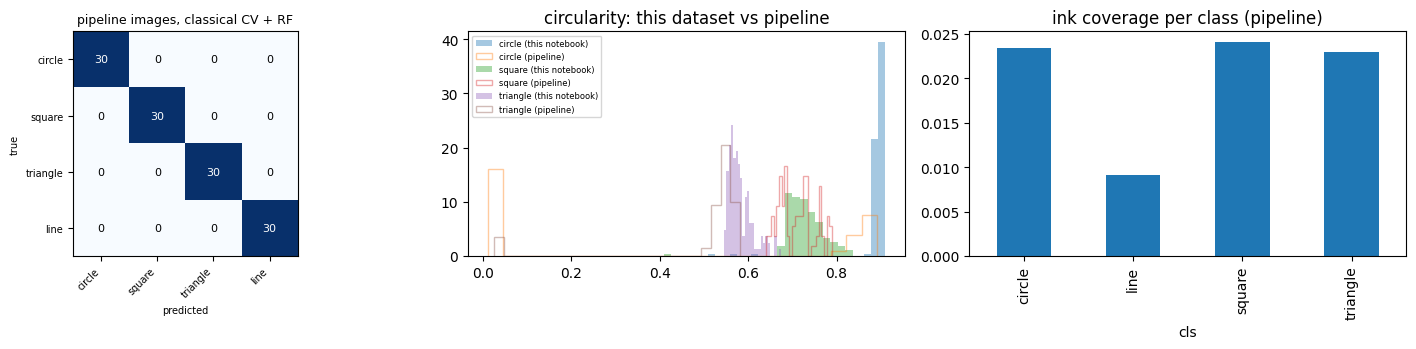

KS tests, same class in the two datasets (small p = the pipeline images look different): {'circle': '2.6e-57', 'square': '9.9e-07', 'triangle': '7.3e-21'}


In [14]:
# ---------- link to the prosthetic pipeline (modules B/C/E): EDA of its data and a classical-CV baseline on the same images ----------
pf = f"{PIPE_OUT}/data_s0.npz"
if not os.path.exists(pf): print(f"{pf} not found: put this notebook next to the pipeline output folder (or set PIPE_OUT) to run this section")
else:
    z = np.load(pf); PX = {s: z[f"{s}_X"] for s in ("train", "val", "test")}; PY = {s: z[f"{s}_y"] for s in ("train", "val", "test")}; PC = len(PIPE_CLASSES)
    print("pipeline images:", {s: PX[s].shape for s in PX}, "| classes", PIPE_CLASSES); rows = []
    for s in ("train", "test"):
        for img, y in zip(PX[s], PY[s]):
            ft = image_features(img); rows.append({**(ft or {k: np.nan for k in FEATS}), "split": s, "cls": PIPE_CLASSES[y], "ink": float((img > 127).mean())})
    pdf = pd.DataFrame(rows); print(f"classical segmentation worked on {pdf[FEATS[0]].notna().mean():.1%} of the pipeline images"); pdf = pdf.dropna(subset=FEATS)
    print("\nEDA of the pipeline dataset: mean ink coverage and shape features per class"); display(pdf.groupby("cls")[["ink"] + FEATS[:8]].mean().round(3))
    a_tr, a_te = pdf[pdf.split == "train"], pdf[pdf.split == "test"]; pm = RandomForestClassifier(300, random_state=SEED, n_jobs=-1).fit(a_tr[FEATS].values, a_tr.cls.map(PIPE_CLASSES.index).values)
    pp = pm.predict(a_te[FEATS].values); py = a_te.cls.map(PIPE_CLASSES.index).values; cmp_ = cm_np(py, pp, PC)
    print(f"\nclassical-CV + Random Forest on the CLEAN pipeline images (the ceiling that the phosphene classifier E is compared against): accuracy {np.trace(cmp_) / cmp_.sum():.3f} | macro-F1 {macro_f1_cm(cmp_):.3f}")
    display(tpfp_table(py, pp, PIPE_CLASSES).round(3))
    shared = [c for c in PIPE_CLASSES if c in SHAPES]; sub = a_te[a_te.cls.isin(shared)]; pr5 = MD[BEST].predict(sub[FEATS].values); acc5 = np.mean([SHAPES[i] == c for i, c in zip(pr5, sub.cls)])
    print(f"domain shift: our 5-class model ({BEST}) trained on this notebook's shapes, applied to the pipeline's {shared} images (thin white outlines): accuracy {acc5:.3f}")
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6)); plot_cm(ax[0], cmp_, PIPE_CLASSES, "pipeline images, classical CV + RF")
    for c in shared: ax[1].hist(feat[feat.cls == c].circularity, 25, alpha=.4, density=True, label=f"{c} (this notebook)"); ax[1].hist(pdf[pdf.cls == c].circularity, 25, alpha=.4, density=True, histtype="step", label=f"{c} (pipeline)")
    ax[1].set_title("circularity: this dataset vs pipeline"); ax[1].legend(fontsize=6); pdf.groupby("cls").ink.mean().plot.bar(ax=ax[2], title="ink coverage per class (pipeline)"); plt.tight_layout(); plt.show()
    print("KS tests, same class in the two datasets (small p = the pipeline images look different):", {c: f"{stats.ks_2samp(feat[feat.cls == c].circularity, pdf[pdf.cls == c].circularity).pvalue:.1e}" for c in shared})


## 9. Summary

In [15]:
# ---------- summary file for the report / README ----------
summary = dict(dataset=dict(train=int(len(tr)), test=int(len(te)), scenes=int(len(SC)), classes=SHAPES), best_model=BEST,
               test_accuracy={n: float(np.mean(p == yte)) for n, (p, _) in PRED.items()}, test_macro_f1={n: float(macro_f1_cm(cm_np(yte, p))) for n, (p, _) in PRED.items()},
               counting=dict(exact_rate=float(np.mean(err == 0)), mae=float(np.abs(err).mean()), bias=float(err.mean()), det_precision=float(pr_), det_recall=float(rc_),
                             end_to_end_tp_rate=float(SC.cls_correct.sum() / SC.true_count.sum()), slope=float(lg.slope), r2=float(lg.rvalue ** 2)))
json.dump(summary, open(f"{OUT_F}/summary_F.json", "w"), indent=1); print(json.dumps(summary, indent=1)); print("\nall figures and tables are in", OUT_F, "and the dataset folder is", ROOT)


{
 "dataset": {
  "train": 600,
  "test": 200,
  "scenes": 40,
  "classes": [
   "square",
   "circle",
   "triangle",
   "pentagon",
   "hexagon"
  ]
 },
 "best_model": "SVM",
 "test_accuracy": {
  "Rule-based": 0.955,
  "KNN": 0.96,
  "SVM": 0.98,
  "RandomForest": 0.98,
  "LogReg": 0.975
 },
 "test_macro_f1": {
  "Rule-based": 0.954737628336259,
  "KNN": 0.9599329031980357,
  "SVM": 0.9798606076248353,
  "RandomForest": 0.9798606076248353,
  "LogReg": 0.9750375366254133
 },
 "counting": {
  "exact_rate": 0.7,
  "mae": 0.725,
  "bias": -0.725,
  "det_precision": 0.9912280701754386,
  "det_recall": 0.7902097902097902,
  "end_to_end_tp_rate": 0.6923076923076923,
  "slope": 0.7093481790767805,
  "r2": 0.5063461091542473
 }
}

all figures and tables are in analysis_F_quick_s0 and the dataset folder is shapes_dataset_quick_s0
